In [1]:
import shap
import pandas as pd
import xgboost as xgb
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split


In [ ]:
df = pd.read_csv("../../../datasets/balanceados/dataset_total_balanceado.csv")
display(df.head())
display(df.info())

,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Inbound,Label
0,1,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0
1,2,2,62.0,318.0,31.0,31.0,31.0,0.0,159.0,159.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
2,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1
3,3,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
4,2,0,868.0,0.0,434.0,434.0,434.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1


<class 'pandas.DataFrame'>
RangeIndex: 104802 entries, 0 to 104801
Data columns (total 63 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Total Fwd Packets            104802 non-null  int64  
 1   Total Backward Packets       104802 non-null  int64  
 2   Total Length of Fwd Packets  104802 non-null  float64
 3   Total Length of Bwd Packets  104802 non-null  float64
 4   Fwd Packet Length Max        104802 non-null  float64
 5   Fwd Packet Length Min        104802 non-null  float64
 6   Fwd Packet Length Mean       104802 non-null  float64
 7   Fwd Packet Length Std        104802 non-null  float64
 8   Bwd Packet Length Max        104802 non-null  float64
 9   Bwd Packet Length Min        104802 non-null  float64
 10  Bwd Packet Length Mean       104802 non-null  float64
 11  Bwd Packet Length Std        104802 non-null  float64
 12  Flow Bytes/s                 104802 non-null  float64
 13  Flow Packe

None

In [3]:
drop_colunas = ['Inbound', 'Min Packet Length']
df.drop(columns=drop_colunas, inplace=True)
display(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 104802 entries, 0 to 104801
Data columns (total 61 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Total Fwd Packets            104802 non-null  int64  
 1   Total Backward Packets       104802 non-null  int64  
 2   Total Length of Fwd Packets  104802 non-null  float64
 3   Total Length of Bwd Packets  104802 non-null  float64
 4   Fwd Packet Length Max        104802 non-null  float64
 5   Fwd Packet Length Min        104802 non-null  float64
 6   Fwd Packet Length Mean       104802 non-null  float64
 7   Fwd Packet Length Std        104802 non-null  float64
 8   Bwd Packet Length Max        104802 non-null  float64
 9   Bwd Packet Length Min        104802 non-null  float64
 10  Bwd Packet Length Mean       104802 non-null  float64
 11  Bwd Packet Length Std        104802 non-null  float64
 12  Flow Bytes/s                 104802 non-null  float64
 13  Flow Packe

None

In [4]:
x=df.drop(columns=['Label'])
y=df['Label']

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2, random_state=42)

scaler = StandardScaler().set_output(transform="pandas")
x_treino_scaled = scaler.fit_transform(x_treino)   
x_teste_scaled = scaler.transform(x_teste)

amostra_500 = x_teste_scaled.sample(n=500, random_state=42)
amostra_100 = x_teste_scaled.sample(n=100, random_state=42)

DT

In [5]:
modelo_dt = tree.DecisionTreeClassifier(random_state=42)
modelo_dt.fit(x_treino_scaled, y_treino)
y_pred_dt = modelo_dt.predict(x_teste_scaled)
y_pred_dttreino = modelo_dt.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_dttreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia = accuracy_score(y_teste, y_pred_dt)
precisao = precision_score(y_teste, y_pred_dt, average='macro')
recall = recall_score(y_teste, y_pred_dt, average='macro')
f1 = f1_score(y_teste, y_pred_dt, average='macro')
matriz_dt1 = confusion_matrix(y_teste, y_pred_dt)

matriz_confusao_dt1 = pd.DataFrame(
    matriz_dt1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_dt1 = matriz_confusao_dt1.div(matriz_confusao_dt1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia*100):.4f}")
print(f"Precisão:  {(precisao*100):.4f}")
print(f"Recall:    {(recall*100):.4f}")
print(f"F1-Score:  {(f1*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(DT- Holdout):")
print((( matriz_normalizada_dt1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9999
Acurácia:  99.9094
Precisão:  99.9095
Recall:    99.9092
F1-Score:  99.9093

                       MATRIZ DE CONFUSÃO(DT- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.89%                0.11%
Real: 1 (Ataque)                0.08%               99.92%


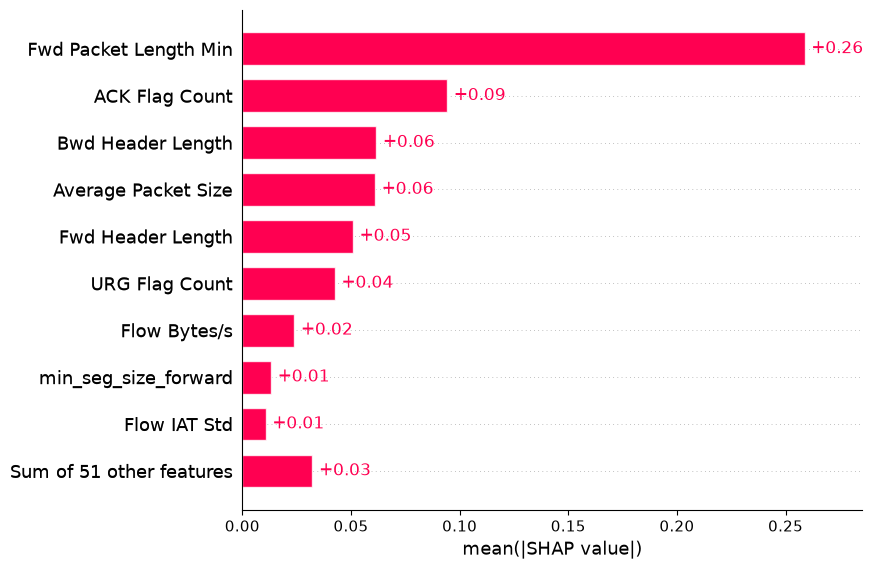

In [7]:
explainer = shap.TreeExplainer(modelo_dt)
shap_values = explainer(amostra_500)

shap.plots.bar(shap_values[:, :, 1])

RF

In [8]:
modelo_rf = RandomForestClassifier(random_state=42, n_jobs=-1)
modelo_rf.fit(x_treino_scaled, y_treino)
y_pred_rf = modelo_rf.predict(x_teste_scaled)
y_pred_rftreino = modelo_rf.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_rftreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_rf = accuracy_score(y_teste, y_pred_rf)
precisao_rf = precision_score(y_teste, y_pred_rf, average='macro')
recall_rf = recall_score(y_teste, y_pred_rf, average='macro')
f1_rf = f1_score(y_teste, y_pred_rf, average='macro')
matriz_rf1 = confusion_matrix(y_teste, y_pred_rf)

matriz_confusao_rf1 = pd.DataFrame(
    matriz_rf1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_rf1 = matriz_confusao_rf1.div(matriz_confusao_rf1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_rf*100):.4f}")
print(f"Precisão:  {(precisao_rf*100):.4f}")
print(f"Recall:    {(recall_rf*100):.4f}")
print(f"F1-Score:  {(f1_rf*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(RF- Holdout):")
print((( matriz_normalizada_rf1)*100).round(2).astype(str) + '%')



Acurácia no conjunto de treino: 0.9999
Acurácia:  99.9284
Precisão:  99.9284
Recall:    99.9285
F1-Score:  99.9284

                       MATRIZ DE CONFUSÃO(RF- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.93%                0.07%
Real: 1 (Ataque)                0.08%               99.92%


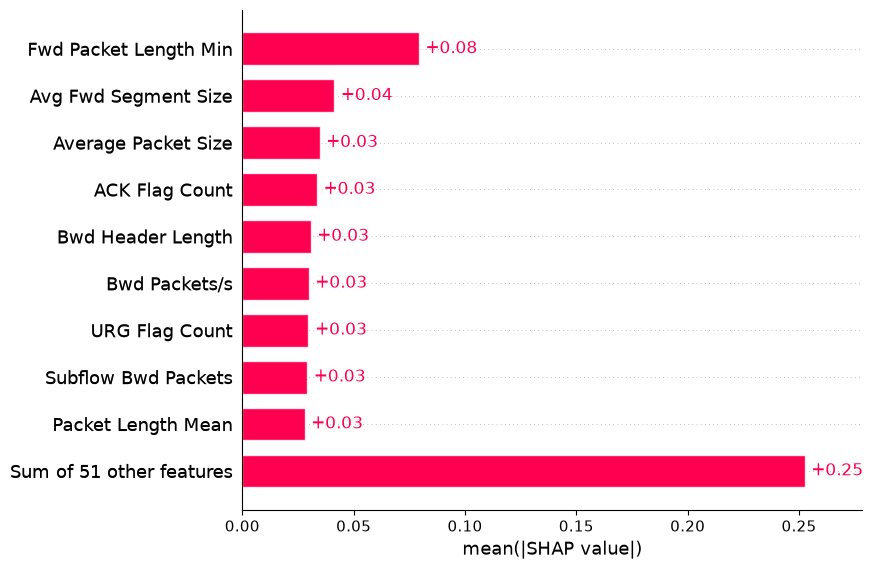

In [9]:
explainer = shap.TreeExplainer(modelo_rf)
shap_values = explainer(amostra_500)        

shap.plots.bar(shap_values[:, :, 1])

XGB

In [12]:
modelo_xgb = xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss')
modelo_xgb.fit(x_treino_scaled, y_treino)
y_pred_xgb = modelo_xgb.predict(x_teste_scaled)
y_pred_xgbtreino = modelo_xgb.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_xgbtreino)
print(f"Acurácia no conjunto de treino: {(acuracia_treino*100):.2f}")

acuracia_xgb = accuracy_score(y_teste, y_pred_xgb)
precisao_xgb = precision_score(y_teste, y_pred_xgb, average='macro')
recall_xgb = recall_score(y_teste, y_pred_xgb, average='macro')
f1_xgb = f1_score(y_teste, y_pred_xgb, average='macro')
matriz_xgb1 = confusion_matrix(y_teste, y_pred_xgb)

matriz_confusao_xgb1 = pd.DataFrame(
    matriz_xgb1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_xgb1 = matriz_confusao_xgb1.div(matriz_confusao_xgb1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_xgb*100):.2f}")
print(f"Precisão:  {(precisao_xgb*100):.2f}")
print(f"Recall:    {(recall_xgb*100):.2f}")
print(f"F1-Score:  {(f1_xgb*100):.2f}")
print("\n                       MATRIZ DE CONFUSÃO(XGB- Holdout):")
print((( matriz_normalizada_xgb1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 99.99
Acurácia:  99.93
Precisão:  99.93
Recall:    99.93
F1-Score:  99.93

                       MATRIZ DE CONFUSÃO(XGB- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.93%                0.07%
Real: 1 (Ataque)                0.08%               99.92%


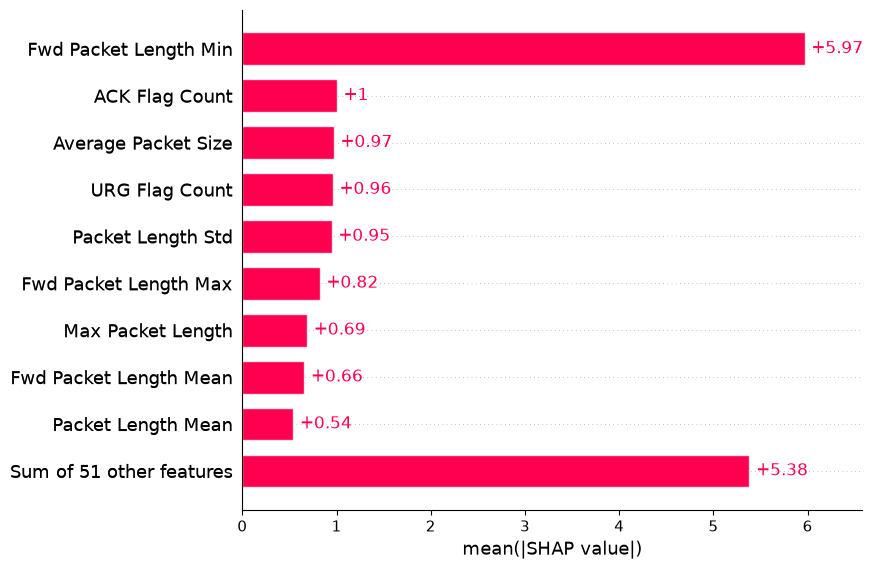

In [14]:
explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer(amostra_500)

shap.plots.bar(shap_values)

SVM

In [15]:
modelo_svm = LinearSVC(random_state=42, max_iter=2000);
modelo_svm.fit(x_treino_scaled, y_treino)
y_pred_svm = modelo_svm.predict(x_teste_scaled)
y_pred_svmtreino = modelo_svm.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_svmtreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_svm = accuracy_score(y_teste, y_pred_svm)
precisao_svm = precision_score(y_teste, y_pred_svm, average='macro')
recall_svm = recall_score(y_teste, y_pred_svm, average='macro')
f1_svm = f1_score(y_teste, y_pred_svm, average='macro')
matriz_svm1 = confusion_matrix(y_teste, y_pred_svm)

matriz_confusao_svm1 = pd.DataFrame(
    matriz_svm1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_svm1 = matriz_confusao_svm1.div(matriz_confusao_svm1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_svm*100):.4f}")
print(f"Precisão:  {(precisao_svm*100):.4f}")
print(f"Recall:    {(recall_svm*100):.4f}")
print(f"F1-Score:  {(f1_svm*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(SVM- Holdout):")
print((( matriz_normalizada_svm1)*100).round(2).astype(str) + '%')



Acurácia no conjunto de treino: 0.9956
Acurácia:  99.6374
Precisão:  99.6379
Recall:    99.6369
F1-Score:  99.6374

                       MATRIZ DE CONFUSÃO(SVM- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.58%                0.42%
Real: 1 (Ataque)                 0.3%                99.7%


Background dataset has 83841 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=83841 when initializing the masker.


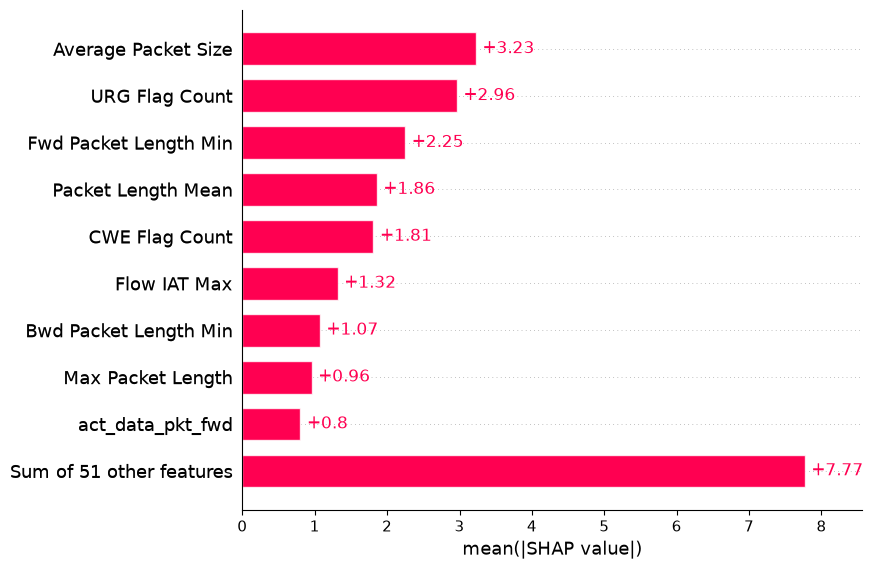

In [16]:
explainer = shap.LinearExplainer(modelo_svm, x_treino_scaled)
shap_values = explainer(amostra_500)

shap.plots.bar(shap_values)    

KNN

In [17]:
modelo_knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
modelo_knn.fit(x_treino_scaled, y_treino)
y_pred_knn = modelo_knn.predict(x_teste_scaled)
y_pred_knntreino = modelo_knn.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_knntreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_knn = accuracy_score(y_teste, y_pred_knn)
precisao_knn = precision_score(y_teste, y_pred_knn, average='macro')
recall_knn = recall_score(y_teste, y_pred_knn, average='macro')
f1_knn = f1_score(y_teste, y_pred_knn, average='macro')
matriz_knn1 = confusion_matrix(y_teste, y_pred_knn)

matriz_confusao_knn1 = pd.DataFrame(
    matriz_knn1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_knn1 = matriz_confusao_knn1.div(matriz_confusao_knn1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_knn*100):.4f}%")
print(f"Precisão:  {(precisao_knn*100):.4f}%")
print(f"Recall:    {(recall_knn*100):.4f}%")
print(f"F1-Score:  {(f1_knn*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (KNN - Holdout):")
print(((matriz_normalizada_knn1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9992
Acurácia:  99.8664%
Precisão:  99.8663%
Recall:    99.8666%
F1-Score:  99.8664%

                   MATRIZ DE CONFUSÃO (KNN - Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.88%                0.12%
Real: 1 (Ataque)                0.15%               99.85%


PermutationExplainer explainer: 101it [06:02,  3.66s/it]                         


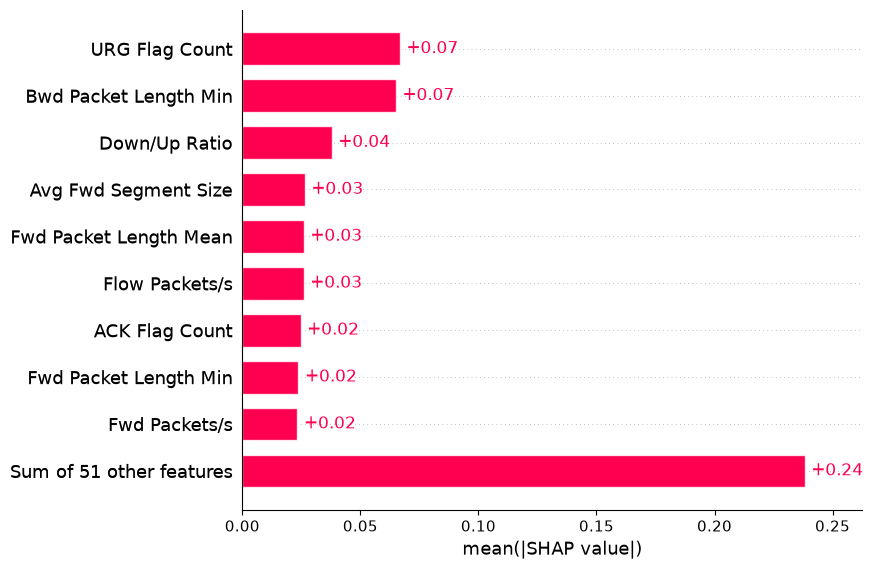

In [18]:
explainer = shap.PermutationExplainer(modelo_knn.predict_proba,shap.sample(x_treino_scaled, 50, random_state=42))
shap_values = explainer(amostra_100)

shap.plots.bar(shap_values[:,:, 1])

MLP

In [19]:
modelo_mlp = MLPClassifier(random_state=42, max_iter=300)
modelo_mlp.fit(x_treino_scaled, y_treino)
y_pred_mlp = modelo_mlp.predict(x_teste_scaled)
y_pred_mlptreino = modelo_mlp.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_mlptreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_mlp = accuracy_score(y_teste, y_pred_mlp)
precisao_mlp = precision_score(y_teste, y_pred_mlp, average='macro')
recall_mlp = recall_score(y_teste, y_pred_mlp, average='macro')
f1_mlp = f1_score(y_teste, y_pred_mlp, average='macro')
matriz_mlp1 = confusion_matrix(y_teste, y_pred_mlp)

matriz_confusao_mlp1 = pd.DataFrame(
    matriz_mlp1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_mlp1 = matriz_confusao_mlp1.div(matriz_confusao_mlp1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_mlp*100):.4f}")
print(f"Precisão:  {(precisao_mlp*100):.4f}")
print(f"Recall:    {(recall_mlp*100):.4f}")
print(f"F1-Score:  {(f1_mlp*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(MLP- Holdout):")
print((( matriz_normalizada_mlp1)*100).round(2).astype(str) + '%')


Acurácia no conjunto de treino: 0.9990
Acurácia:  99.8855
Precisão:  99.8850
Recall:    99.8861
F1-Score:  99.8855

                       MATRIZ DE CONFUSÃO(MLP- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.96%                0.04%
Real: 1 (Ataque)                0.19%               99.81%


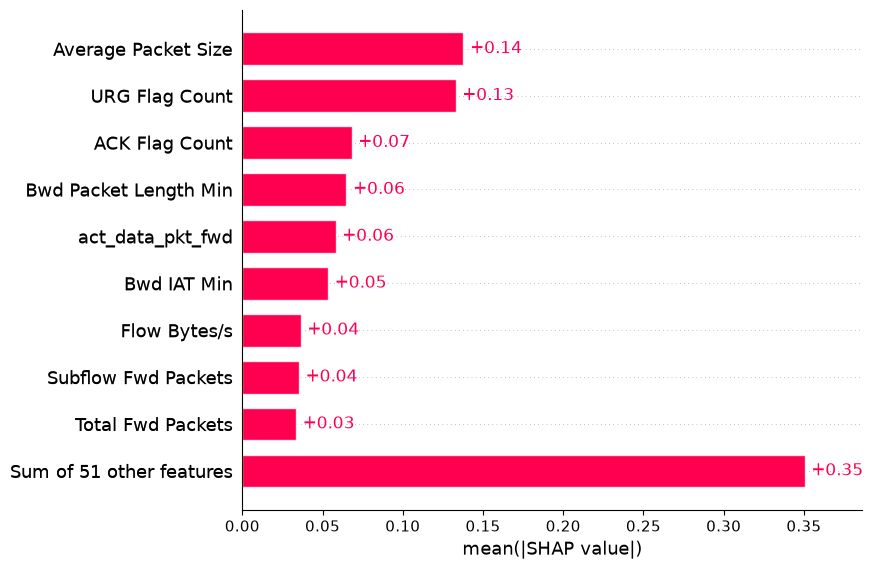

In [20]:
explainer = shap.PermutationExplainer(modelo_mlp.predict_proba,shap.sample(x_treino_scaled, 50, random_state=42))
shap_values = explainer(amostra_100)

shap.plots.bar(shap_values[:, :, 1])